# W11A B · 구조·참조·내 callback으로 편집 앱 조립하기

2026-11-09 · 『핸즈온 생성형 AI』8장 · 7장 실습 보완과 연결

새 Colab 사본에서 처음부터 독립 실행합니다. 필수 경로는 CPU입니다. 개인 사진·API 키·유료 GPU·이전 노트북 파일은 필요 없습니다. 패키지0.1.18 / `2026-fall-w11a`에 데이터·사전학습 소형 checkpoint·실제 SD 기록이 포함됩니다. 최초 설치는 네트워크가 필요하며 이후 캐시를 재사용합니다. 실패를 성공 그림으로 대체하지 않습니다.

**현재 실행**은 28×28 class denoiser와 수치 계산입니다. **SD 기록 분석**은 CPU에서 실제 실행해 보관한 SD1.5 결과를 읽습니다. SDXL·T4 현재 실행으로 해석하지 않습니다. 소형 모델과 전체 SD 결과의 품질·속도를 직접 비교하지 않습니다.

각 핵심 코드는 이 화면에 펼쳐 두었습니다. 읽기용 발췌와 import 원본의 SHA를 제작 단계에서 대조합니다. 독립 연습의 `my_...=None`은 다음 셀 실행을 막지 않습니다.

[강의노트](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11a/course/notion/w11a/w11a-lesson.md) · [계산 기록지](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11a/course/notion/w11a/w11a-workbook.md) · [7장 A 개선판](https://colab.research.google.com/github/lunalab-ai/genAI/blob/2026-fall-w11a/notebooks/student/w10b_diffusion_adaptation.ipynb)


In [ ]:
#@title 설치·런타임 준비 { display-mode: "form" }
import sys, subprocess, os, json, uuid
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
PUBLIC_REF='2026-fall-w11a'
try: ready=version('luna-genai')=='0.1.18'
except PackageNotFoundError: ready=False
if not ready:
    if 'luna_genai' in sys.modules: raise RuntimeError('런타임을 재시작하고 첫 셀부터 실행하세요.')
    local=Path('src/pyproject.toml').exists()
    package=str(Path('src').resolve())+'[image-editing]' if local else 'luna-genai[image-editing] @ git+https://github.com/lunalab-ai/genAI.git@'+PUBLIC_REF+'#subdirectory=src'
    subprocess.run([sys.executable,'-m','pip','install','-q']+(['-e'] if local else [])+[package],check=True)
from luna_genai.runtime import prepare_text_runtime
prepare_text_runtime(repair_optional=True)
import torch, numpy as np, pandas as pd
from PIL import Image
from IPython.display import display
torch.set_num_threads(4)
IN_COLAB='COLAB_RELEASE_TAG' in os.environ
RUN_ID=uuid.uuid4().hex[:8]
print('Python',sys.version.split()[0],'package',version('luna-genai'),'CUDA',torch.cuda.is_available())


## 1. 구조 조건과 이미지 참조는 어디로 들어가는가?

ControlNet은 edge/depth/pose 같은 공간 조건으로 만든 residual을 U-Net 중간 feature에 더합니다. 강도를 높여도 지시 이행·품질이 자동으로 좋아지지 않습니다. SD1.5 Canny와 SDXL depth 모델은 교환 가능한 파일이 아닙니다.

IP-Adapter는 CLIP image feature를 projection한 이미지 조건을 별도 attention 경로에 넣습니다. CLIP의 전역 의미 특징은 정확한 위치 좌표가 아닙니다. 단순 이미지 변형/유사도와 IP-Adapter는 다른 용도입니다.

$$h'=h+s_c r,\qquad A=\operatorname{softmax}(QK^T/\sqrt d)V$$
$$A_{combined}=A_{text}+s_i A_{image}$$

독립 softmax 두 개를 더하는 구조를 한 softmax에 token을 모두 넣는 것과 구별합니다. 아래 작은 계산은 구조의 교육용 분해이며 pretrained adapter 자체가 아닙니다.


**실제 구현 펼쳐 보기 · `separate_attention`**

[고정 버전 정의](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11a/src/luna_genai/image_editing.py#L97) · 아래 코드는 같은 소스에서 자동 발췌한 읽기용 코드입니다. 실행은 import한 원본 함수를 호출합니다.

```python
    factor = query.shape[1] ** -.5
    at = (query @ text_key.T * factor).softmax(-1)
    ai = (query @ image_key.T * factor).softmax(-1)
    text, image = at @ text_value, ai @ image_value
    return {'text_weights': at, 'image_weights': ai, 'text': text, 'image': image,
            'combined': text + scale * image}
```


In [ ]:
from luna_genai.image_editing import separate_attention,add_control,load_edit_records
q=torch.zeros((1,1));kt=torch.zeros((2,1));vt=torch.tensor([[2.],[4.]])
ki=torch.zeros((2,1));vi=torch.tensor([[10.],[14.]])
attention=separate_attention(q,kt,vt,ki,vi,scale=.5)
print({k:v.tolist() for k,v in attention.items()})
print('control residual example',add_control(torch.tensor([1.,2.]),torch.tensor([.2,-.4]),scale=2))
my_attention=None;my_residual=None


### 8B1 · 두 attention 분모를 수계산

Q=0이고 text value=[1,5], image value=[8,12], image scale .25일 때 combined를 계산하세요. 네 token을 한 softmax에 넣은 평균과 비교하세요.

힌트: 각 branch는 자기 token 안에서 합이1입니다.

자가 점검: 예측·관측·통제 조건·한계를 각각 한 문장으로 적으세요.


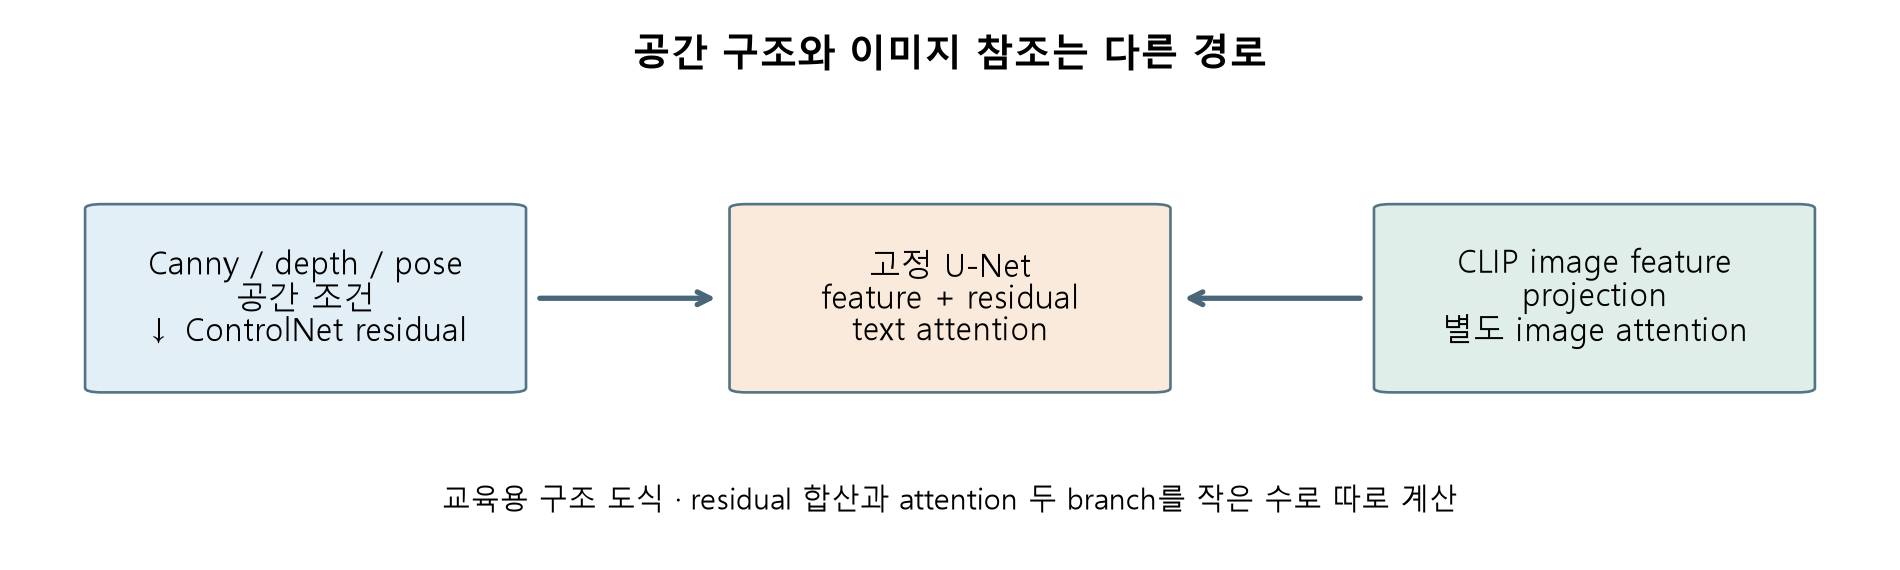


[Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w11a/course/notion/w11a/assets/07-control-reference.png)


실제 전체 SD 호출 경로도 아래에 펼쳐 둡니다. 필수 CPU 경로에서는 사전 실행 기록을 읽으며, 아래 loader를 현재 다시 실행한 것으로 표시하지 않습니다.

**실제 구현 펼쳐 보기 · `make_edit_pipeline`**

[고정 버전 정의](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11a/src/luna_genai/image_editing_live.py#L42) · 아래 코드는 같은 소스에서 자동 발췌한 읽기용 코드입니다. 실행은 import한 원본 함수를 호출합니다.

```python
        if kind == 'control':
            control = ControlNetModel.from_pretrained(CONTROL_ID, revision=CONTROL_REVISION,
                variant='fp16', torch_dtype=dtype, local_files_only=offline, use_safetensors=True)
            pipe = StableDiffusionControlNetPipeline.from_pipe(base, controlnet=control).to(device)
```


**실제 구현 펼쳐 보기 · `attach_ip_adapter`**

[고정 버전 정의](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11a/src/luna_genai/image_editing_live.py#L67) · 아래 코드는 같은 소스에서 자동 발췌한 읽기용 코드입니다. 실행은 import한 원본 함수를 호출합니다.

```python
    from transformers import CLIPVisionModelWithProjection
    # IP-Adapter installs its own attention processors. SlicedAttnProcessor
    # cannot be reconstructed by the 0.40.0 adapter converter without slice_size.
    pipe.disable_attention_slicing()
    encoder = CLIPVisionModelWithProjection.from_pretrained(IP_ID, revision=IP_REVISION,
        subfolder='models/image_encoder', local_files_only=offline,
        dtype=pipe.unet.dtype, use_safetensors=True).to(pipe.device)
    pipe.register_modules(image_encoder=encoder)
    pipe.load_ip_adapter(IP_ID, revision=IP_REVISION, subfolder='models',
        weight_name='ip-adapter_sd15.safetensors', local_files_only=offline,
        image_encoder_folder='models/image_encoder')
    return pipe
```


## 2. 같은 seed로 2×2 실험 읽기

구조 사용 여부×참조 사용 여부의 네 셀을 읽습니다. prompt·seed42·SD1.5 revision·8step·256px는 고정했습니다. SD CPU에서 실제 실행한 기록입니다. 지금 노트북에서는 모델 전체를 다시 생성하지 않습니다. 매우 짧은 저해상도 출력은 좋은 결과나 인과 효과의 일반화를 보장하지 않습니다.

CLIP의 image feature를 쓰더라도 내용·스타일·배치가 얽힐 수 있습니다. 교재의 SDXL style 설정 `up.block_0`와 layout `down.block_2`는 특정 architecture 경로이며 SD1.5에 그대로 복사하지 않습니다.


In [ ]:
from luna_genai.image_editing_app import record_view,tiny_view,build_edit_app,export_observation,observation_note
record=load_edit_records();directory=record['directory']
display(Image.open(directory/'canny.png'));display(Image.open(directory/'reference.png'))
cells=[]
for c in (False,True):
    for i in (False,True):
        image,payload=record_view(c,i);display(image)
        cells.append(payload['record'])
display(pd.DataFrame(cells)[['id','control_scale','ip_scale','seed','seconds']])
my_controls=None;my_new_case=None


### 8B2 · 조건 통제와 새 사례

가방 모양은 유지하면서 색감만 참조하려 합니다. 네 셀에서 무엇을 관찰하고 다음 실험에서 어느 인자 하나를 바꿀지 적으세요. depth 모델을 Canny 입력에 그대로 적용해도 되나요?

힌트: 현재 관찰과 다음 가설을 구별하세요.

자가 점검: 예측·관측·통제 조건·한계를 각각 한 문장으로 적으세요.


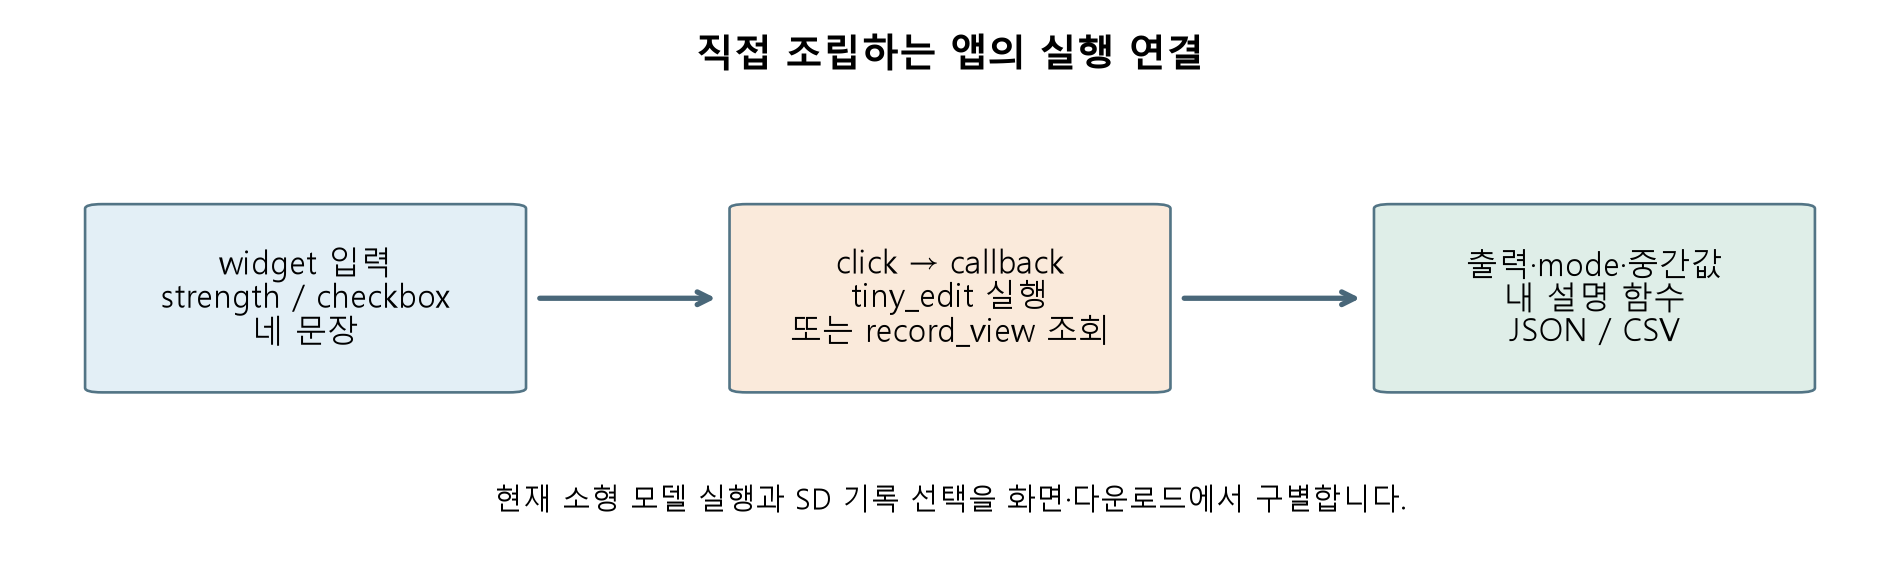


[Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w11a/course/notion/w11a/assets/09-app-wiring.png)


## 3. 내가 조립하는 마지막 앱

입력 widget → `.click()` → callback → 공통 알고리즘 → 이미지·중간값·설정 → 다운로드 순서입니다. 첫 탭은 소형 모델을 현재 실행하고, 둘째는 실제 SD 기록을 선택합니다. 자동으로 두 모드를 바꾸지 않습니다.

`tiny_view(model, clean, strength, reverse)`는 PIL·DataFrame·dict를 반환합니다. `record_view(control,reference)`는 기록 이미지·dict를 반환하며 SD를 실행하지 않습니다. `export_observation(payload,note)`는 새로운 JSON·CSV 파일을 씁니다. `build_edit_app`은 앱을 만들고 `launch`는 별도입니다.


**실제 구현 펼쳐 보기 · `tiny_view`**

[고정 버전 정의](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11a/src/luna_genai/image_editing_app.py#L17) · 아래 코드는 같은 소스에서 자동 발췌한 읽기용 코드입니다. 실행은 import한 원본 함수를 호출합니다.

```python
    mask = torch.zeros_like(clean); mask[:, :, 8:23, 8:23] = 1
    if reverse:
        mask = 1 - mask
    result = tiny_edit(model, clean, strength=strength, mask=mask, steps=20)
    image = np.rint((result['images'][0, 0].clamp(-1, 1).numpy() + 1) * 127.5).astype('uint8')
    metrics = region_mse(clean[0].permute(1, 2, 0).numpy(), result['images'][0].permute(1, 2, 0).numpy(), mask[0, 0].numpy())
    settings = {k: result[k] for k in ('mode', 'strength', 'seed', 'executed_steps')}
```


In [ ]:
from luna_genai.diffusion_adaptation import TinyAdaptationLab,load_teaching_images
model=TinyAdaptationLab('frozen').model;clean=load_teaching_images()['train'][:1]
tiny_image,trace,tiny_payload=tiny_view(model,clean,.6,False)
display(tiny_image);display(trace.head());print(tiny_payload)
# 완성 기본 함수와 독립 연습 변수를 분리합니다.
learner_note=observation_note
my_note_function=None


### 8B3 · 설명 callback 구현

`learner_note(prediction, observed, held_fixed, limitation)`을 직접 작성하세요. 반환 문자열에 네 항목과 현재 기록 분석 모드를 표시하고, build_edit_app의 note_fn에 연결하세요. Gradio의 입력 순서가 함수 인자 순서와 일치하는지도 확인하세요.

힌트: 표시 문구를 바꾸는 것과 sampling 알고리즘 변경을 구별하세요.

자가 점검: 예측·관측·통제 조건·한계를 각각 한 문장으로 적으세요.


**실제 구현 펼쳐 보기 · `build_edit_app`**

[고정 버전 정의](https://github.com/lunalab-ai/genAI/blob/2026-fall-w11a/src/luna_genai/image_editing_app.py#L71) · 아래 코드는 같은 소스에서 자동 발췌한 읽기용 코드입니다. 실행은 import한 원본 함수를 호출합니다.

```python
            control = gr.Checkbox(value=True, label='Canny ControlNet .8')
            reference = gr.Checkbox(value=True, label='IP-Adapter .6')
            show = gr.Button('저장된 2×2 실험 셀 보기')
            sd_image = gr.Image(value=full[0], label='실제 SD1.5 사전 실행 기록 · 현재 생성 아님')
            payload = gr.JSON(value=full[1], label='모델·seed·설정·실측 시간')
            show.click(record_view, [control, reference], [sd_image, payload], api_name='record_cell')
```


In [ ]:
app=build_edit_app(model,clean,note_fn=learner_note)
app.launch(share=IN_COLAB,prevent_thread_lock=True,quiet=True)
print('앱 주소:',app.share_url if IN_COLAB else app.local_url)
# 인라인 JavaScript 오류면 새 셀에서 print(app.share_url) 후 새 탭으로 엽니다.
_,payload=record_view(True,True)
files=export_observation(payload,learner_note('윤곽 유지 예상','실제 그림 관찰 후 입력','seed42','한 표본·8step'))
for path in files:display(Path(path).name)
my_app_change=None


### 8B4 · 실제 알고리즘 인자 변경

이 노트북의 tiny_view 호출에서 strength .6→.3으로 바꾸고 현재 실행의 trace 행 수를 확인하세요. 앱의 기록 선택 checkbox가 SD를 새로 생성하지 않는 이유와 JSON에서 확인할 필드도 적으세요.

힌트: 소형 모델은 steps20, count=int(20×strength)입니다.

자가 점검: 예측·관측·통제 조건·한계를 각각 한 문장으로 적으세요.


## 선택 · 무료 GPU가 실제 할당되었을 때만 현재 SD 생성

기본 False입니다. True로 바꾸면 **실제 CUDA 장치가 없으면 오류**로 멈춥니다. 최초 SD1.5 약2.6GB, ControlNet/IP 사용 시 추가 수GB·수분이 필요합니다. 이 셀은 image2image만 실행합니다. 더 큰 SDXL/CosXL은 교재의 별도 선택 확장으로 이번 CPU 검증 범위에 포함되지 않습니다. GPU 메모리·할당을 보장하지 않습니다.


In [ ]:
RUN_LIVE_SD=False
if RUN_LIVE_SD:
    from luna_genai.image_editing_live import make_edit_pipeline,checked_generate
    live=make_edit_pipeline('img2img',device='cuda')
    live_result=checked_generate(live,prompt='an illustration of a red tote bag on a wooden table',image=Image.open(directory/'source.png'),strength=.6,num_inference_steps=20,guidance_scale=6)
    display(live_result['image']);print({k:v for k,v in live_result.items() if k!='image'})
else: print('현재 full SD GPU 생성 미실행. 위 full SD 그림은 실제 CPU 사전 실행 기록입니다.')


In [ ]:
assert attention['combined'].item()==9.
assert len(cells)==4 and len({x['seed'] for x in cells})==1
assert all(x['safety_checked'] and x['device']=='cpu' for x in cells)
assert len(trace)==12 and tiny_payload['region_mse']['outside']==0.
saved=json.loads(Path(files[0]).read_text(encoding='utf-8'))
assert saved['experiment']['record']['id']=='control1-ip1'
assert Path(files[1]).stat().st_size>100 and len(app.config['dependencies'])>=4
print('W11A_B_RUNTIME_PASS · attention hand calculation / 2x2 actual SD records / tiny callback / JSON CSV')
if not IN_COLAB:app.close()
